In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [2]:
df = pd.read_csv('../datasets/heart.csv')

We can use df.plt.x() to visit different views of our dataset. x can be bar or hist or etc.

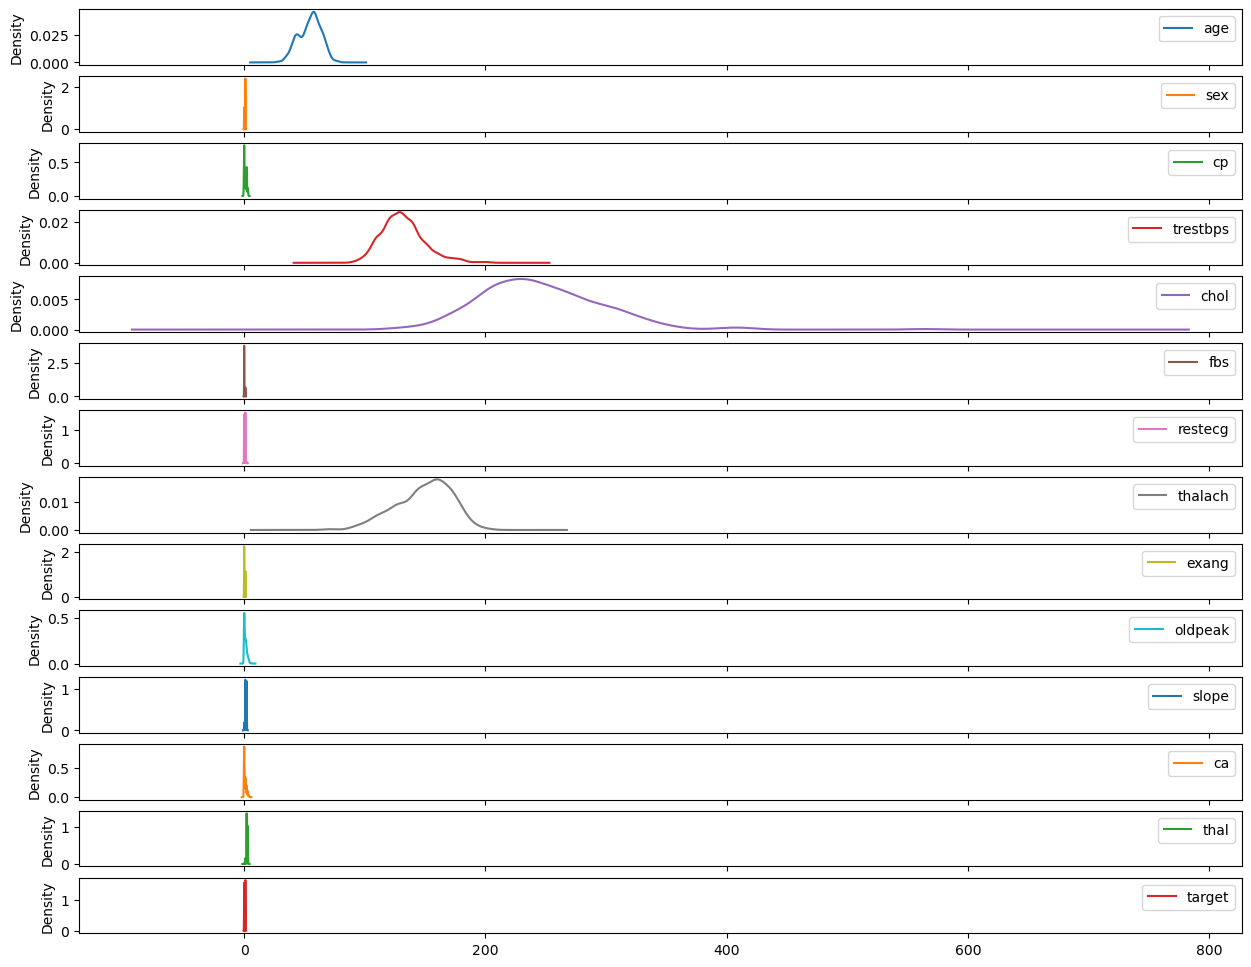

In [3]:
df.plot.kde(figsize=(15,12),subplots=True);

we can use this type of setup to view the distribution of the data. whether it is boolean, normal, or bimodal distribution

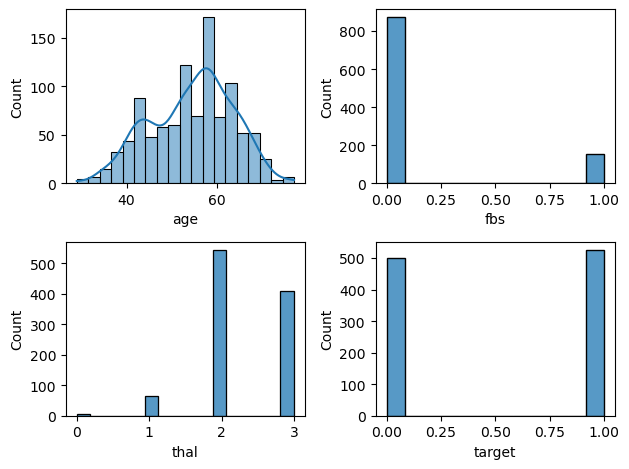

In [4]:
fig, axes= plt.subplots(2,2)

sns.histplot(df["age"],ax=axes[0,0], kde=True)
sns.histplot(df["fbs"],ax=axes[0,1])
sns.histplot(df["thal"],ax=axes[1,0])
sns.histplot(df["target"],ax=axes[1,1])

plt.tight_layout()
plt.show()

the matplotlib does have a built in .plot(kind='scatter') plot to show data and also we can select c to see how it changes based on a range of colors

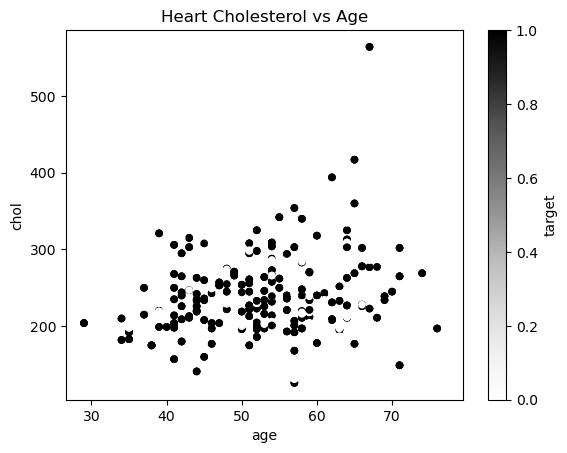

In [5]:
df.plot(kind='scatter',x='age',y='chol',c='target', title='Heart Cholesterol vs Age');

sns also has that with a different syntax

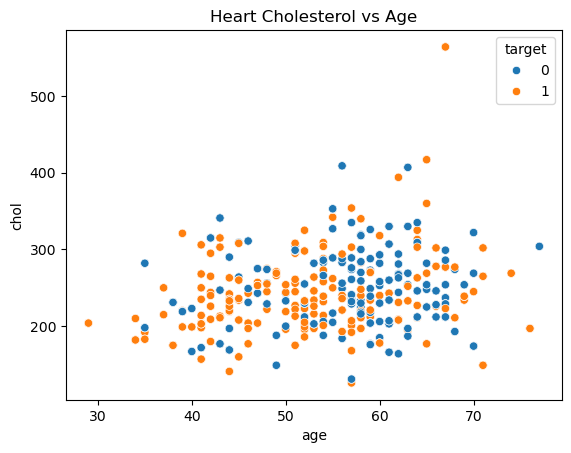

In [6]:
sns.scatterplot(data=df, x='age', y='chol', hue='target')
plt.title('Heart Cholesterol vs Age');

in both cases we can set horizental and vertical lines to see where the data lands

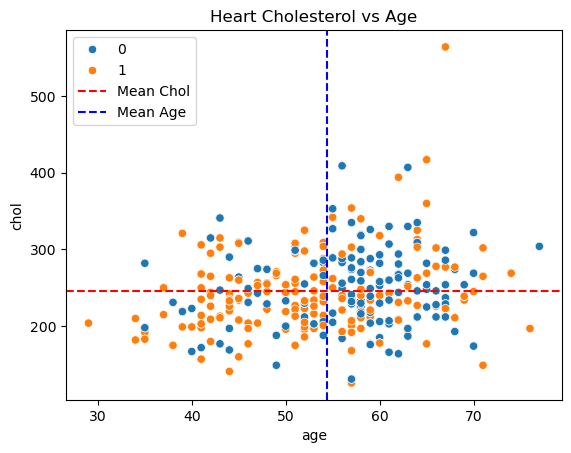

In [7]:
sns.scatterplot(data=df, x='age', y='chol', hue='target')
plt.title('Heart Cholesterol vs Age')
plt.axhline(df['chol'].mean(), color='red', linestyle='--', label='Mean Chol')
plt.axvline(df['age'].mean(), color='blue', linestyle='--', label='Mean Age')
plt.legend();

to see the relationship between the features, we use a heatmap, in the code below, the corr variable is actually a table of the values. we can just use that to see the numbers. but to visualize it easier we use plots and colorways. matplotlib cant show the number with syntax but we can force it with a 2 dimension loop.

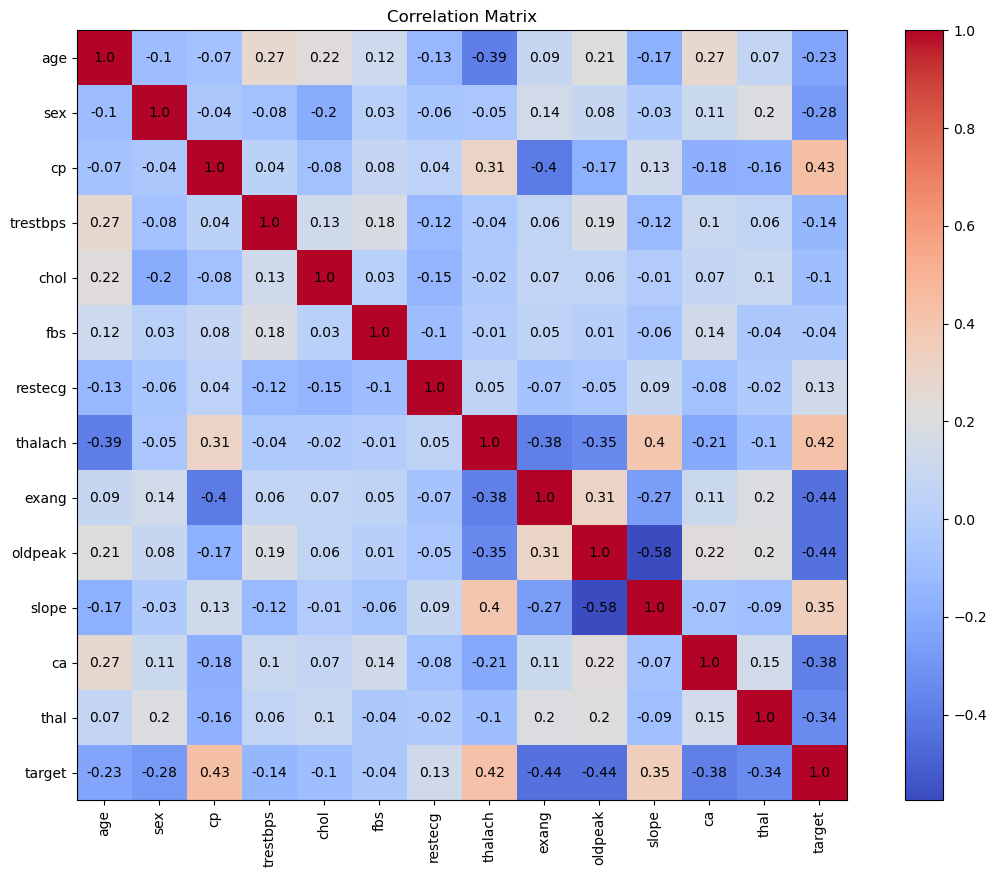

In [8]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(15, 10))
plt.imshow(corr, cmap='coolwarm', interpolation='none')
plt.colorbar()
plt.xticks(ticks=np.arange(len(corr.columns)), labels=corr.columns, rotation=90)
plt.yticks(ticks=np.arange(len(corr.columns)), labels=corr.columns)
plt.title("Correlation Matrix")
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        plt.text(j, i, round(corr.iloc[i, j], 2),
                 ha='center', va='center', color='black')

much easier to do so with sns. we can use heatmap(annot=True)

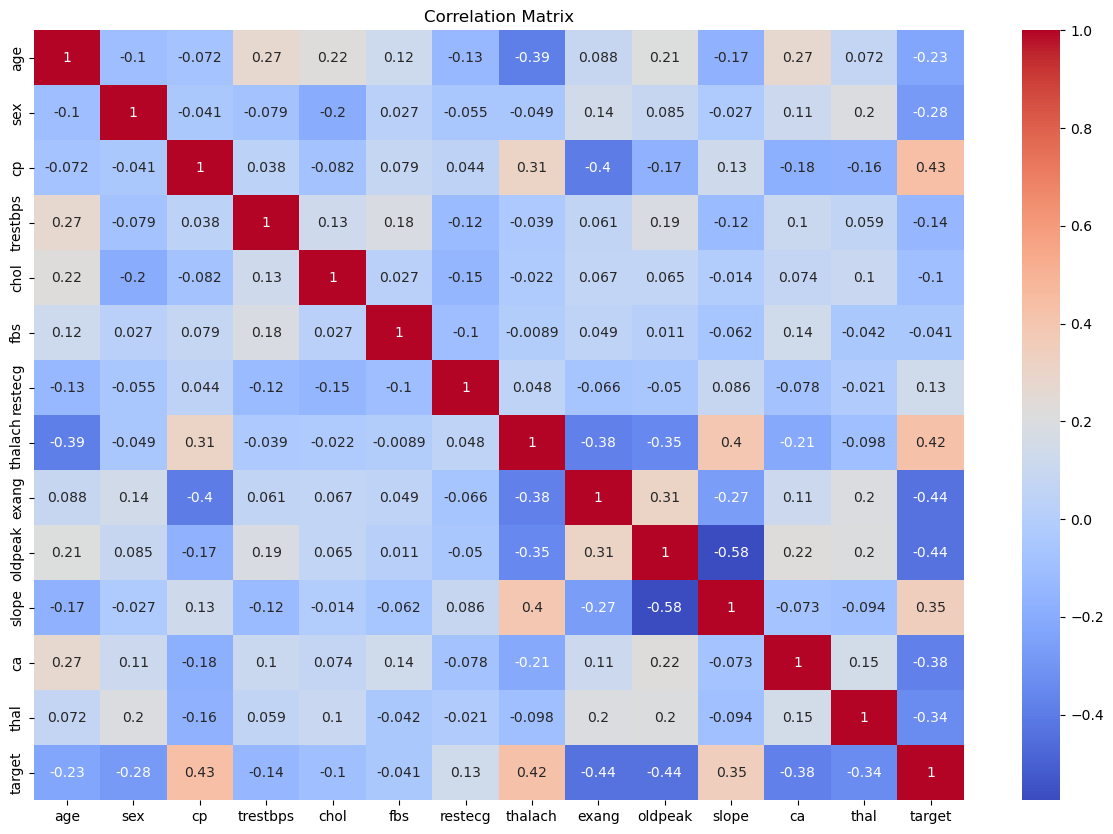

In [9]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(15,10))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title("Correlation Matrix");

we also can just see the relationships between a single feature and all others. here is the vertical plot.

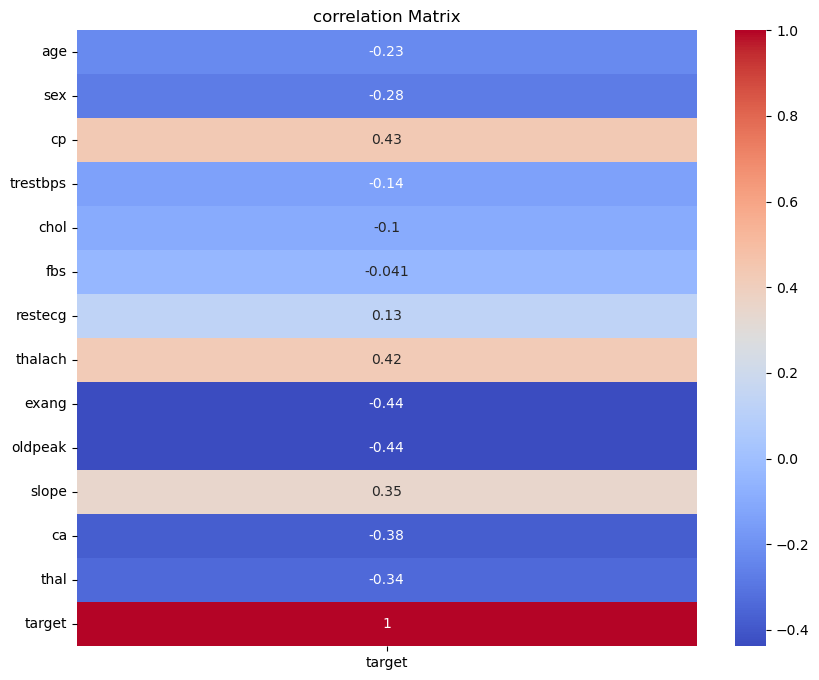

In [10]:
plt.figure(figsize=(10, 8))
corr = df.corr(numeric_only=True)
sns.heatmap(corr[['target']],annot=True,cmap='coolwarm')
plt.title("correlation Matrix");

we can use .T (transpose) to make it horizental

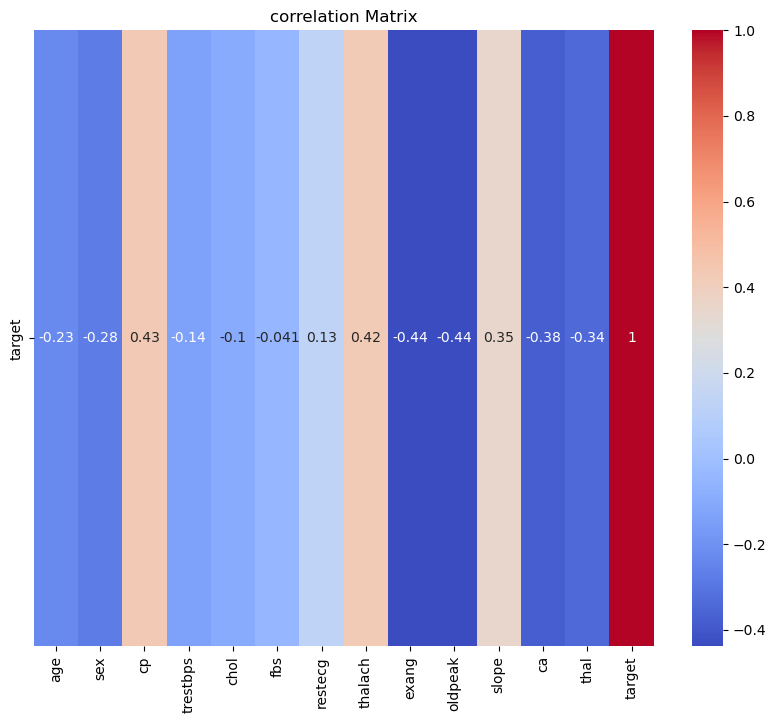

In [11]:
plt.figure(figsize=(10, 8))
corr = df.corr(numeric_only=True)
sns.heatmap(corr[['target']].T,annot=True,cmap='coolwarm')
plt.title("correlation Matrix");

we can also use a barplot and also use geometry to show the direction of the data.(redundant imo)

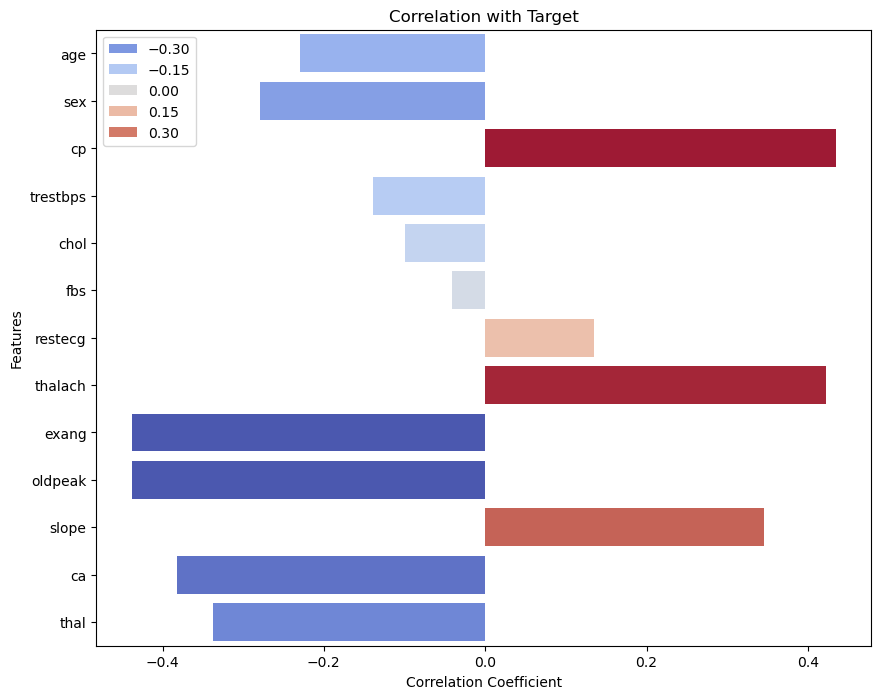

In [12]:
plt.figure(figsize=(10, 8))
corr_target = df.corr(numeric_only=True)['target'].drop('target')
sns.barplot(x=corr_target.values, y=corr_target.index, hue=corr_target.values, palette='coolwarm')
plt.title('Correlation with Target')
plt.xlabel('Correlation Coefficient')
plt.ylabel('Features');

ok so we know binary features, like male or female ( in this context) or below 50 age and above 50 age. but what about features taht have like only 3 or 4 values? we can convert that boolean feature into multiple binary features. we first see how many unique values are in each features using a loop.

In [13]:
for i in df.columns:
    print(i, len(df[i].unique()))

age 41
sex 2
cp 4
trestbps 49
chol 152
fbs 2
restecg 3
thalach 91
exang 2
oldpeak 40
slope 3
ca 5
thal 4
target 2


we use 'slope' as an example. we use pd.get_dummies() method to do so.

In [14]:
df_dummied = pd.get_dummies(df, columns=['slope'], drop_first=True)
df_dummied

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,ca,thal,target,slope_1,slope_2
0,52,1,0,125,212,0,1,168,0,1.0,2,3,0,False,True
1,53,1,0,140,203,1,0,155,1,3.1,0,3,0,False,False
2,70,1,0,145,174,0,1,125,1,2.6,0,3,0,False,False
3,61,1,0,148,203,0,1,161,0,0.0,1,3,0,False,True
4,62,0,0,138,294,1,1,106,0,1.9,3,2,0,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1020,59,1,1,140,221,0,1,164,1,0.0,0,2,1,False,True
1021,60,1,0,125,258,0,0,141,1,2.8,1,3,0,True,False
1022,47,1,0,110,275,0,0,118,1,1.0,1,2,0,True,False
1023,50,0,0,110,254,0,0,159,0,0.0,0,2,1,False,True
